# 0.2 Data pipeline for localization: GRAZPEDWRI-DX

Builds on the `0.1` output in `data/processed/`. Nothing is reprocessed, so run `0.1` first.

| Output | Contents |
|---|---|
| `processed/graz_cell_targets.npz` | `objectness` (20327, 32, 16) int8 and `distances` (20327, 32, 16, 4) float32, same row order as `graz.csv` |
| `models/0.2_data-pipeline-localization_fahim/location-prior/` | `val_cell_predictions.npz`, `test_cell_predictions.npz` |
| `processed/graz_cast_pairs.csv` | one row per extra train image: a fracture-free crop of a cast image, or its partner crop with the fracture |
| `processed/graz_cast_pairs_256x512_u8.npy` | the extra images, uint8, (n_extra, 512, 256), same row order as `graz_cast_pairs.csv` |
| `processed/graz_cast_pairs_boxes.csv` | fracture boxes on the partner crops, same columns as `graz_boxes.csv` |
| `processed/graz_cast_pairs_cell_targets.npz` | cell targets for the extra images |
| `processed/yolo_dataset/` | PNGs, YOLO label files, `data.yaml`, `data_all-castpairs.yaml` (only if `MAKE_YOLO_EXPORT`) |

Grid: 32 rows x 16 columns of 16x16 px cells. Cell `(i, j)` has its center at `x = 16*j + 8`, `y = 16*i + 8`.

Order: part 1 (load), part 3a and 3b (cell targets of the originals, location prior), part 2 (cast pairs), part 3c (cell targets of the cast pairs), part 4 (YOLO export).
Parts 3a and 3b come before part 2 because they need only the `0.1` output.

In [1]:
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from tqdm import tqdm

from snap.config import MODELS_DIR, PROCESSED_DATA_DIR

SEED = 42
GRID_ROWS = 32
GRID_COLS = 16
CELL_SIZE = 16
RING_PAD = 0.5                      # pad each side by 50% of the box width/height
IGNORE_NAMES = ['periostealreaction']
VERSIONS_PER_IMAGE = 1              # crop pairs per source image; 2 doubles the extra set
MIN_BAND_HEIGHT = 128               # px; shorter fracture-free bands are skipped
LOST_AREA_LIMIT = 0.5               # skip a pair if a box keeps less than this share of its area after the edit
NOFRACTURE_EXTRA_SCALE = (1.0, 1.0)    # off: a zoom on label 0 only widened its zoom range, which revealed the label
FLIP_CHANCE = 0.0                   # off: the two crops of a pair already look different
MAX_ANGLE = 0                       # off: 0.1 already rotated the images upright
SCALE_RANGE = (0.9, 1.1)            # zoom out / in
GAIN_RANGE = (0.9, 1.1)             # contrast
OFFSET_RANGE = (-10, 10)            # brightness, in gray levels
MAKE_YOLO_EXPORT = True             # False skips part 4 (only the YOLO path needs it)

IMAGE_W = 256
IMAGE_H = 512
NOTEBOOK_DIR = MODELS_DIR / '0.2_data-pipeline-localization_fahim'
PRIOR_DIR = NOTEBOOK_DIR / 'location-prior'
YOLO_DIR = PROCESSED_DATA_DIR / 'yolo_dataset'

for name in ['graz.csv', 'graz_256x512_u8.npy', 'graz_boxes.csv']:
    assert (PROCESSED_DATA_DIR / name).exists(), f'{name} is missing: run 0.1 first'

2026-11-20 22:28:07.167 | INFO     | snap.config:<module>:11 - PROJ_ROOT path is: E:\CCNY\CSC I1910\Project\wrist-fracture-detection


## 1. Load the 0.1 output

The images are already windowed, cleaned of L/R markers, rotated upright, cropped and fit to 256x512 with black padding.
The boxes are already in the 256x512 frame. Box lists below are `(x0, y0, x1, y1)` in pixels.

In [2]:
graz = pd.read_csv(PROCESSED_DATA_DIR / 'graz.csv')
images = np.load(PROCESSED_DATA_DIR / 'graz_256x512_u8.npy', mmap_mode='r')
boxes = pd.read_csv(PROCESSED_DATA_DIR / 'graz_boxes.csv')
assert images.shape == (len(graz), IMAGE_H, IMAGE_W)

fracture_boxes = boxes[boxes['name'] == 'fracture']
ignore_boxes = boxes[boxes['name'].isin(IGNORE_NAMES)]
FRACTURE_CLS = int(fracture_boxes['cls'].iloc[0])


def boxes_by_image(box_table):
    """Dict from filestem to its list of (x0, y0, x1, y1)."""
    result = {}
    for row in box_table.itertuples():
        if row.filestem not in result:
            result[row.filestem] = []
        result[row.filestem].append((row.x0, row.y0, row.x1, row.y1))
    return result


fracture_by_image = boxes_by_image(fracture_boxes)
ignore_by_image = boxes_by_image(ignore_boxes)

print(graz['split'].value_counts().to_dict())
print(f'{len(fracture_boxes)} fracture boxes, {len(ignore_boxes)} ignore boxes')

{'train': 14182, 'val': 3202, 'test': 2943}
18090 fracture boxes, 3453 ignore boxes


Two random images from each fracture and cast group, with the fracture boxes in red. The title shows the group size.

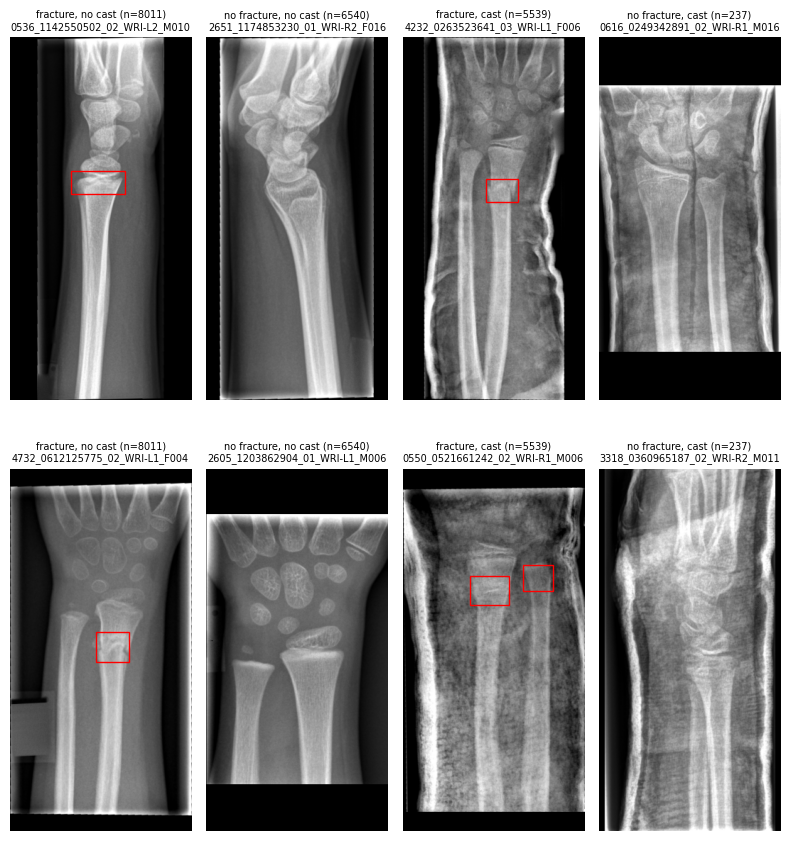

In [3]:
def draw_boxes(ax, box_list, color, style='-'):
    for x0, y0, x1, y1 in box_list:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linestyle=style, linewidth=1))


# (title, label, cast)
PREVIEW_GROUPS = [
    ('fracture, no cast', 1, 0),
    ('no fracture, no cast', 0, 0),
    ('fracture, cast', 1, 1),
    ('no fracture, cast', 0, 1),
]
PREVIEW_PER_GROUP = 2
preview_rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(PREVIEW_PER_GROUP, len(PREVIEW_GROUPS), figsize=(8, 9))
for column, (group_name, label, cast) in enumerate(PREVIEW_GROUPS):
    in_group = (graz['label'] == label) & (graz['cast'] == cast)
    group_rows = np.nonzero(in_group.to_numpy())[0]
    picks = preview_rng.choice(group_rows, size=PREVIEW_PER_GROUP, replace=False)
    for plot_row, row_number in enumerate(picks):
        ax = axes[plot_row, column]
        filestem = graz.at[row_number, 'filestem']
        ax.imshow(images[row_number], cmap='gray')
        draw_boxes(ax, fracture_by_image.get(filestem, []), 'red')
        ax.set_title(f'{group_name} (n={len(group_rows)})\n{filestem}', fontsize=7)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 3a. Cell targets for the original images

Per cell, from its center:
- `1`: inside a fracture box (wins over `-1`)
- `-1` (ignore): inside a fracture box padded by 50% on each side but not inside the box, or inside a `periostealreaction` box
- `0`: everything else

`distances` holds, for positive cells only, the pixels from the cell center to the left, top, right and bottom edges of the smallest fracture box that contains the center.
A center on a box edge counts as inside, so the distances are never negative.

In [4]:
def center_inside(cx, cy, box):
    x0, y0, x1, y1 = box
    return x0 <= cx <= x1 and y0 <= cy <= y1


def pad_box(box):
    x0, y0, x1, y1 = box
    pad_x = RING_PAD * (x1 - x0)
    pad_y = RING_PAD * (y1 - y0)
    return (x0 - pad_x, y0 - pad_y, x1 + pad_x, y1 + pad_y)


def box_area(box):
    x0, y0, x1, y1 = box
    return max(0, x1 - x0) * max(0, y1 - y0)


def cell_center(i, j):
    return CELL_SIZE * j + CELL_SIZE / 2, CELL_SIZE * i + CELL_SIZE / 2

In [5]:
def make_targets(fracture_boxes, ignore_boxes):
    """Cell targets for one image: objectness (32, 16) and distances (32, 16, 4)."""
    objectness = np.zeros((GRID_ROWS, GRID_COLS), dtype=np.int8)
    distances = np.zeros((GRID_ROWS, GRID_COLS, 4), dtype=np.float32)

    for i in range(GRID_ROWS):
        for j in range(GRID_COLS):
            cx, cy = cell_center(i, j)

            for box in fracture_boxes:
                if center_inside(cx, cy, pad_box(box)):
                    objectness[i, j] = -1
            for box in ignore_boxes:
                if center_inside(cx, cy, box):
                    objectness[i, j] = -1

            containing = []
            for box in fracture_boxes:
                if center_inside(cx, cy, box):
                    containing.append(box)
            if len(containing) > 0:
                objectness[i, j] = 1  # fracture wins over ignore
                x0, y0, x1, y1 = min(containing, key=box_area)
                distances[i, j] = [cx - x0, cy - y0, x1 - cx, y1 - cy]

    return objectness, distances

Targets for all 20,327 images, saved in the same row order as `graz.csv`.

In [6]:
n_images = len(graz)
objectness = np.zeros((n_images, GRID_ROWS, GRID_COLS), dtype=np.int8)
distances = np.zeros((n_images, GRID_ROWS, GRID_COLS, 4), dtype=np.float32)

for row_number, filestem in enumerate(tqdm(graz['filestem'])):
    image_fracture_boxes = fracture_by_image.get(filestem, [])
    image_ignore_boxes = ignore_by_image.get(filestem, [])
    objectness[row_number], distances[row_number] = make_targets(image_fracture_boxes, image_ignore_boxes)

np.savez_compressed(PROCESSED_DATA_DIR / 'graz_cell_targets.npz', objectness=objectness, distances=distances)


  0%|          | 0/20327 [00:00<?, ?it/s]


  2%|▏         | 332/20327 [00:00<00:06, 3033.68it/s]


  3%|▎         | 709/20327 [00:00<00:05, 3270.74it/s]


  5%|▌         | 1073/20327 [00:00<00:05, 3349.17it/s]


  7%|▋         | 1446/20327 [00:00<00:05, 3489.07it/s]


  9%|▉         | 1796/20327 [00:00<00:05, 3382.03it/s]

... (48 outputs left out)


 96%|█████████▌| 19463/20327 [00:05<00:00, 3198.99it/s]


 97%|█████████▋| 19786/20327 [00:05<00:00, 3112.68it/s]


 99%|█████████▉| 20100/20327 [00:06<00:00, 2968.29it/s]


100%|██████████| 20327/20327 [00:06<00:00, 3318.53it/s]

Checks:
- label-0 images have no 1s
- at most one fractured image has no positive cell
- at most one box has no cell center inside it
- the distances decode back to a true box and are never negative

In [7]:
def check_targets(objectness, distances, labels, box_lists):
    """Asserts on a set of cell targets. Returns how many fractured images have no positive cell."""
    no_positive = 0
    for k in range(len(labels)):
        positive = objectness[k] == 1
        if labels[k] == 0:
            assert positive.sum() == 0, f'image {k} is label 0 but has positive cells'
            continue
        if positive.sum() == 0:
            no_positive += 1

        for i, j in zip(*np.nonzero(positive)):
            cx, cy = cell_center(i, j)
            l, t, r, b = distances[k, i, j]
            assert min(l, t, r, b) >= 0
            decoded = np.array([cx - l, cy - t, cx + r, cy + b])
            matches = False
            for box in box_lists[k]:
                if np.abs(decoded - np.array(box)).max() < 1e-3:
                    matches = True
            assert matches, f'image {k}, cell ({i}, {j}) does not decode to a true box'

    assert (distances[objectness != 1] == 0).all()
    return no_positive

In [8]:
def boxes_without_center(box_lists):
    count = 0
    for box_list in box_lists:
        for box in box_list:
            has_center = False
            for i in range(GRID_ROWS):
                for j in range(GRID_COLS):
                    cx, cy = cell_center(i, j)
                    if center_inside(cx, cy, box):
                        has_center = True
            if not has_center:
                count += 1
    return count


original_box_lists = [fracture_by_image.get(filestem, []) for filestem in graz['filestem']]
no_positive = check_targets(objectness, distances, graz['label'].to_numpy(), original_box_lists)
no_center = boxes_without_center(original_box_lists)
print(f'fractured images with no positive cell: {no_positive}; fracture boxes with no cell center: {no_center}')
assert no_positive <= 1 and no_center <= 1

fractured images with no positive cell: 0; fracture boxes with no cell center: 1


Positive and ignored cells per split.

In [9]:
def target_table(objectness, labels, groups):
    """One row per group: images, fractured, positive cells per fractured image, share of -1 cells."""
    rows = []
    for group in pd.unique(groups):
        in_group = groups == group
        fractured = in_group & (labels == 1)
        positives = (objectness[fractured] == 1).sum(axis=(1, 2))
        rows.append({
            'set': group,
            'images': int(in_group.sum()),
            'fractured': int(fractured.sum()),
            'mean positive cells': positives.mean(),
            'median positive cells': np.median(positives),
            'share of 1 cells': (objectness[in_group] == 1).mean(),
            'share of -1 cells': (objectness[in_group] == -1).mean(),
        })
    return pd.DataFrame(rows)


target_table(objectness, graz['label'].to_numpy(), graz['split'].to_numpy()).round(4)

,set,images,fractured,mean positive cells,median positive cells,share of 1 cells,share of -1 cells
0,val,3202,2208,12.4991,12.0,0.0168,0.0488
1,train,14182,9443,12.1017,11.0,0.0157,0.0460
2,test,2943,1899,12.0237,11.0,0.0152,0.0437


Train fractured images have a median of 11 positive cells; 1.6% of all train cells are positive.

## 3b. Location prior

A baseline that ignores the image: at each cell center, the number of train fracture boxes (originals only) that contain it, divided by the largest count.
Its distances are half the median train box width (`l`, `r`) and half the median height (`t`, `b`), the same for every cell and image.
Saved in the same format as every model's predictions.

12642 train fracture boxes; distances l, t, r, b = [26.8 18.5 26.8 18.5]
val: 3202 images saved


test: 2943 images saved


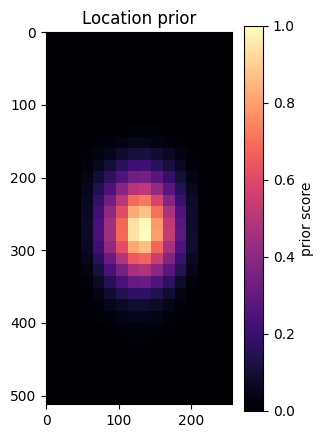

In [10]:
train_filestems = set(graz.loc[graz['split'] == 'train', 'filestem'])
train_fracture_boxes = fracture_boxes[fracture_boxes['filestem'].isin(train_filestems)]

prior_counts = np.zeros((GRID_ROWS, GRID_COLS))
for box in train_fracture_boxes[['x0', 'y0', 'x1', 'y1']].itertuples(index=False):
    for i in range(GRID_ROWS):
        for j in range(GRID_COLS):
            cx, cy = cell_center(i, j)
            if center_inside(cx, cy, box):
                prior_counts[i, j] += 1
prior_scores = (prior_counts / prior_counts.max()).astype(np.float32)

half_width = np.median(train_fracture_boxes['x1'] - train_fracture_boxes['x0']) / 2
half_height = np.median(train_fracture_boxes['y1'] - train_fracture_boxes['y0']) / 2
prior_distances = np.array([half_width, half_height, half_width, half_height], dtype=np.float32)
print(f'{len(train_fracture_boxes)} train fracture boxes; distances l, t, r, b = {prior_distances}')

PRIOR_DIR.mkdir(parents=True, exist_ok=True)
for split in ['val', 'test']:
    rows = np.nonzero((graz['split'] == split).to_numpy())[0]
    scores = np.zeros((len(rows), GRID_ROWS, GRID_COLS), dtype=np.float32)
    split_distances = np.zeros((len(rows), GRID_ROWS, GRID_COLS, 4), dtype=np.float32)
    for k in range(len(rows)):
        scores[k] = prior_scores
        split_distances[k] = prior_distances
    np.savez_compressed(PRIOR_DIR / f'{split}_cell_predictions.npz', rows=rows, scores=scores, distances=split_distances)
    print(f'{split}: {len(rows)} images saved')

plt.figure(figsize=(3, 5))
plt.imshow(prior_scores, extent=(0, IMAGE_W, IMAGE_H, 0), cmap='magma')
plt.colorbar(label='prior score')
plt.title('Location prior')
plt.show()

## 2. Extra cast images: fracture-free crops and their partners

Cast images with no fracture are rare (170 in train). Each train cast image with a fracture (and no `periostealreaction` box, a fracture sign outside the box) gives a pair of crops:
- `crop-no-fracture` (label 0): the taller band of rows above or below the fracture area. It never touches a fracture.
- `crop-with-fracture` (label 1): a band of the same height that contains the whole fracture area.

A crop keeps full-width rows at the original scale, moved to the middle of a black 256x512 image, so the label cannot be read from the band position.
Both crops of a pair get the same random zoom and brightness change. Flip and rotation are off. The two crops already differ, and 0.1 already rotated the images upright. The label-0 crop gets no extra zoom (`NOFRACTURE_EXTRA_SCALE = (1.0, 1.0)`), so both labels share one zoom range.
The bands use only the non-black rows of the source, so label-0 crops do not get more black padding than their partners.

Label 0 here is a fracture-free crop of a cast wrist, not a normal wrist.

In [11]:
def content_rows(image):
    """First and last + 1 row that is not all black."""
    nonblack = np.nonzero(image.max(axis=1) > 0)[0]
    return int(nonblack[0]), int(nonblack[-1]) + 1


def grow_rows(box):
    """Top and bottom row of a fracture box grown by RING_PAD on each side, clipped to the image."""
    x0, y0, x1, y1 = box
    pad = RING_PAD * (y1 - y0)
    return max(0, y0 - pad), min(IMAGE_H, y1 + pad)


def fracture_area(box_list):
    """Rows from the top of the highest grown box to the bottom of the lowest."""
    tops = []
    bottoms = []
    for box in box_list:
        top, bottom = grow_rows(box)
        tops.append(top)
        bottoms.append(bottom)
    return int(np.floor(min(tops))), int(np.ceil(max(bottoms)))


def center_band(image, band_top, band_bottom):
    """Copy the band's rows into the middle of an all-black image."""
    crop = np.zeros_like(image)
    center_top = (IMAGE_H - (band_bottom - band_top)) // 2
    crop[center_top:center_top + band_bottom - band_top] = image[band_top:band_bottom]
    return crop, center_top


def edit_matrix(angle, scale):
    # cv2 puts pixel centers on whole numbers, so the image center is ((W - 1) / 2, (H - 1) / 2)
    return cv2.getRotationMatrix2D(((IMAGE_W - 1) / 2, (IMAGE_H - 1) / 2), angle, scale)


def apply_edits(crop, flip, matrix, gain, offset):
    if flip:
        crop = cv2.flip(crop, 1)
    warped = cv2.warpAffine(crop, matrix, (IMAGE_W, IMAGE_H), flags=cv2.INTER_LINEAR, borderValue=0)
    was_black = warped == 0
    edited = np.clip(np.round(warped.astype(np.float32) * gain + offset), 0, 255).astype(np.uint8)
    edited[was_black] = 0
    return edited


def transform_box(box, flip, matrix):
    """Flip and warp a box the same way as the image: move its 4 corners, take min/max."""
    x0, y0, x1, y1 = box
    if flip:
        x0, x1 = IMAGE_W - x1, IMAGE_W - x0
    xs = []
    ys = []
    for x, y in [(x0, y0), (x1, y0), (x0, y1), (x1, y1)]:
        # box edges sit half a pixel off cv2's pixel centers
        px = x - 0.5
        py = y - 0.5
        xs.append(matrix[0, 0] * px + matrix[0, 1] * py + matrix[0, 2] + 0.5)
        ys.append(matrix[1, 0] * px + matrix[1, 1] * py + matrix[1, 2] + 0.5)
    return min(xs), min(ys), max(xs), max(ys)


def clip_box(box):
    x0, y0, x1, y1 = box
    return max(0, x0), max(0, y0), min(IMAGE_W, x1), min(IMAGE_H, y1)

Box transform checks: with no flip, angle 0 and scale 1 a box stays the same.
With a flip and a rotation, the transformed box must match the extent of a white rectangle warped with the image (within interpolation error).

In [12]:
test_box = (40.3, 100.7, 120.2, 180.9)
same_box = transform_box(test_box, False, edit_matrix(0, 1))
assert np.abs(np.array(same_box) - np.array(test_box)).max() < 1e-6

mask = np.zeros((IMAGE_H, IMAGE_W), dtype=np.uint8)
mask[100:181, 40:120] = 255                       # pixels 40..119, 100..180, i.e. edges (40, 100, 120, 181)
test_matrix = edit_matrix(8, 1.05)
warped_mask = apply_edits(mask, True, test_matrix, 1.0, 0)
mask_ys, mask_xs = np.nonzero(warped_mask > 127)
mask_box = (mask_xs.min(), mask_ys.min(), mask_xs.max() + 1, mask_ys.max() + 1)
moved_box = transform_box((40, 100, 120, 181), True, test_matrix)
print('warped mask extent', mask_box, 'transformed box', np.round(moved_box, 1))
assert np.abs(np.array(mask_box) - np.array(moved_box)).max() < 1.5

warped mask extent (np.int64(114), np.int64(81), np.int64(208), np.int64(177)) transformed box [113.5  80.9 208.5 176.8]


The loop uses one random generator and makes `VERSIONS_PER_IMAGE` pairs per source image.
A source is skipped if its fracture-free band is shorter than `MIN_BAND_HEIGHT` or than the fracture area. A pair is skipped if a fracture box loses more than half its area to clipping after the edit.

In [13]:
periosteal_filestems = set(boxes.loc[boxes['name'] == 'periostealreaction', 'filestem'])
is_pool = (graz['split'] == 'train') & (graz['label'] == 1) & (graz['cast'] == 1) & ~graz['filestem'].isin(periosteal_filestems)
pool = graz[is_pool]
print(f'pool: {len(pool)} train cast images with a fracture and no periostealreaction box')

rng = np.random.default_rng(SEED)
pair_rows = []
pair_images = []
pair_box_rows = []
skipped = {'band shorter than MIN_BAND_HEIGHT': 0, 'band shorter than fracture area': 0, 'box lost over half its area': 0}
plot_info = {}

for source in tqdm(pool.itertuples(), total=len(pool)):
    image = np.asarray(images[source.Index])
    source_boxes = fracture_by_image[source.filestem]

    content_top, content_bottom = content_rows(image)
    area_top, area_bottom = fracture_area(source_boxes)
    area_top = max(area_top, content_top)
    area_bottom = min(area_bottom, content_bottom)

    # fracture-free band: the taller of the content rows above and below the fracture area
    if area_top - content_top >= content_bottom - area_bottom:
        band_top, band_bottom = content_top, area_top
    else:
        band_top, band_bottom = area_bottom, content_bottom
    band_height = band_bottom - band_top

    if band_height < MIN_BAND_HEIGHT:
        skipped['band shorter than MIN_BAND_HEIGHT'] += 1
        continue
    if band_height < area_bottom - area_top:
        skipped['band shorter than fracture area'] += 1
        continue

    for box in source_boxes:
        grown_top, grown_bottom = grow_rows(box)
        assert band_bottom <= grown_top or band_top >= grown_bottom, 'fracture-free band overlaps a grown fracture box'
    plot_info[source.filestem] = (area_top, area_bottom)

    # partner band: same height, contains the whole fracture area, inside the content rows
    lowest_start = max(content_top, area_bottom - band_height)
    highest_start = min(area_top, content_bottom - band_height)
    assert lowest_start <= highest_start

    for version in range(VERSIONS_PER_IMAGE):
        partner_top = int(rng.integers(lowest_start, highest_start + 1))
        partner_bottom = partner_top + band_height
        flip = bool(rng.random() < FLIP_CHANCE)
        angle = rng.uniform(-MAX_ANGLE, MAX_ANGLE)
        scale = rng.uniform(*SCALE_RANGE)
        gain = rng.uniform(*GAIN_RANGE)
        offset = rng.uniform(*OFFSET_RANGE)
        extra_scale = rng.uniform(*NOFRACTURE_EXTRA_SCALE)

        nofracture_crop, center_top = center_band(image, band_top, band_bottom)
        fracture_crop, partner_center_top = center_band(image, partner_top, partner_bottom)
        assert partner_center_top == center_top
        shift_y = center_top - partner_top

        matrix = edit_matrix(angle, scale)
        nofracture_matrix = edit_matrix(angle, scale * extra_scale)  # extra zoom in the same warp

        new_boxes = []
        lost_area = False
        for x0, y0, x1, y1 in source_boxes:
            moved = transform_box((x0, y0 + shift_y, x1, y1 + shift_y), flip, matrix)
            clipped = clip_box(moved)
            if box_area(clipped) < LOST_AREA_LIMIT * box_area(moved):
                lost_area = True
            new_boxes.append(clipped)
        if lost_area:
            skipped['box lost over half its area'] += 1
            continue

        shared = {
            'source_filestem': source.filestem, 'patient_id': source.patient_id, 'split': 'train',
            'cast': 1, 'follow_up': source.follow_up, 'clean': 0,
            'flip': int(flip), 'angle': angle, 'scale': scale, 'gain': gain, 'offset': offset,
        }
        pair_rows.append({
            'filestem': f'{source.filestem}_nofracture{version}', 'label': 0, 'kind': 'crop-no-fracture',
            'band_top': band_top, 'band_bottom': band_bottom, 'shift_y': center_top - band_top,
            'extra_scale': extra_scale, **shared,
        })
        pair_images.append(apply_edits(nofracture_crop, flip, nofracture_matrix, gain, offset))

        fracture_filestem = f'{source.filestem}_fracture{version}'
        pair_rows.append({
            'filestem': fracture_filestem, 'label': 1, 'kind': 'crop-with-fracture',
            'band_top': partner_top, 'band_bottom': partner_bottom, 'shift_y': shift_y,
            'extra_scale': 1.0, **shared,
        })
        pair_images.append(apply_edits(fracture_crop, flip, matrix, gain, offset))
        for x0, y0, x1, y1 in new_boxes:
            pair_box_rows.append({
                'filestem': fracture_filestem, 'cls': FRACTURE_CLS, 'name': 'fracture',
                'x0': round(x0, 2), 'y0': round(y0, 2), 'x1': round(x1, 2), 'y1': round(y1, 2),
            })


COLUMNS = ['filestem', 'source_filestem', 'patient_id', 'split', 'label', 'cast', 'follow_up', 'clean', 'kind',
           'band_top', 'band_bottom', 'shift_y', 'flip', 'angle', 'scale', 'gain', 'offset', 'extra_scale']
cast_pairs = pd.DataFrame(pair_rows)[COLUMNS]
cast_pair_images = np.stack(pair_images)
cast_pair_boxes = pd.DataFrame(pair_box_rows)[list(boxes.columns)]

cast_pairs.to_csv(PROCESSED_DATA_DIR / 'graz_cast_pairs.csv', index=False)
np.save(PROCESSED_DATA_DIR / 'graz_cast_pairs_256x512_u8.npy', cast_pair_images)
cast_pair_boxes.to_csv(PROCESSED_DATA_DIR / 'graz_cast_pairs_boxes.csv', index=False)

print(f'pairs made: {len(cast_pairs) // 2}; extra images: {cast_pair_images.shape}')
print('skipped:', skipped)

pool: 3611 train cast images with a fracture and no periostealreaction box



  0%|          | 0/3611 [00:00<?, ?it/s]


  3%|▎         | 102/3611 [00:00<00:03, 926.77it/s]


  6%|▌         | 201/3611 [00:00<00:03, 958.24it/s]


  8%|▊         | 305/3611 [00:00<00:03, 981.90it/s]


 11%|█▏        | 415/3611 [00:00<00:03, 977.94it/s]

... (29 outputs left out)


 97%|█████████▋| 3496/3611 [00:03<00:00, 973.13it/s]


100%|█████████▉| 3601/3611 [00:03<00:00, 990.81it/s]


100%|██████████| 3611/3611 [00:03<00:00, 985.62it/s]

pairs made: 3509; extra images: (7018, 512, 256)
skipped: {'band shorter than MIN_BAND_HEIGHT': 69, 'band shorter than fracture area': 32, 'box lost over half its area': 1}


Checks: the extra images come only from train patients, a pair shares band height and center row, every partner crop keeps a fracture box,
and the crops of both labels have about the same share of all-black rows.

In [14]:
assert set(cast_pairs['source_filestem']) <= train_filestems
val_test_patients = set(graz.loc[graz['split'] != 'train', 'patient_id'])
assert not set(cast_pairs['patient_id']) & val_test_patients

nofracture_rows = cast_pairs[cast_pairs['label'] == 0].reset_index(drop=True)
fracture_rows = cast_pairs[cast_pairs['label'] == 1].reset_index(drop=True)
assert (nofracture_rows['source_filestem'] == fracture_rows['source_filestem']).all()
nofracture_height = nofracture_rows['band_bottom'] - nofracture_rows['band_top']
fracture_height = fracture_rows['band_bottom'] - fracture_rows['band_top']
assert (nofracture_height == fracture_height).all()
center_top = (IMAGE_H - nofracture_height) // 2
assert (nofracture_rows['band_top'] + nofracture_rows['shift_y'] == center_top).all()
assert (fracture_rows['band_top'] + fracture_rows['shift_y'] == center_top).all()

assert set(cast_pair_boxes['filestem']) == set(fracture_rows['filestem'])
assert len(cast_pair_images) == len(cast_pairs)

# row number of each filestem, for looking up images
graz_row_of = {}
for row_number, filestem in enumerate(graz['filestem']):
    graz_row_of[filestem] = row_number
pair_row_of = {}
for row_number, filestem in enumerate(cast_pairs['filestem']):
    pair_row_of[filestem] = row_number


def black_row_share(image):
    """Share of the rows in an image that are all black."""
    return (image.max(axis=1) == 0).mean()


# measured on the saved crops, so a label-dependent zoom or band height would show up here
nofracture_black = []
fracture_black = []
for pair in range(len(nofracture_rows)):
    nofracture_black.append(black_row_share(cast_pair_images[pair_row_of[nofracture_rows.at[pair, 'filestem']]]))
    fracture_black.append(black_row_share(cast_pair_images[pair_row_of[fracture_rows.at[pair, 'filestem']]]))
print(f'all-black rows: crop-no-fracture {np.mean(nofracture_black):.3f}, crop-with-fracture {np.mean(fracture_black):.3f}')
assert abs(np.mean(nofracture_black) - np.mean(fracture_black)) < 0.01  # within 1 percentage point
print(f'median band height: {nofracture_height.median():.0f} px')

train_before = graz.loc[graz['split'] == 'train', 'label'].value_counts().sort_index()
train_after = train_before + cast_pairs['label'].value_counts().sort_index()
print(pd.DataFrame({'train before': train_before, 'train after': train_after}))
cast_normals = ((graz['split'] == 'train') & (graz['cast'] == 1) & (graz['label'] == 0)).sum()
print(f'train cast images with no fracture: {cast_normals} -> {cast_normals + len(nofracture_rows)}')

all-black rows: crop-no-fracture 0.573, crop-with-fracture 0.573
median band height: 218 px
       train before  train after
label                           
0              4739         8248
1              9443        12952
train cast images with no fracture: 170 -> 3679


One example pair for each case: label-0 band above the fracture (frontal, lateral) and below it (lateral). Left column: the source with the fracture area in red and the label-0 band in cyan.

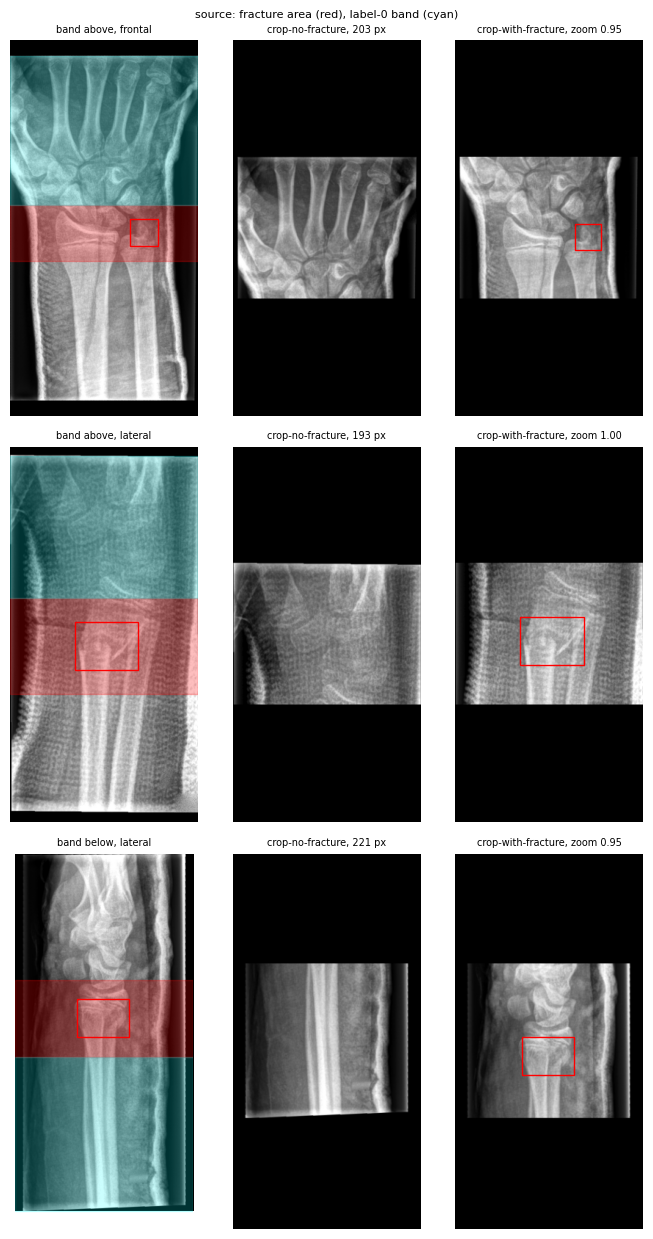

In [15]:
cast_pair_box_lists = boxes_by_image(cast_pair_boxes)
# one pair per case
CASES = ['band above, frontal', 'band above, lateral', 'band below, lateral']
candidates = {}
for case in CASES:
    candidates[case] = []
for pair in range(len(nofracture_rows)):
    source_stem = nofracture_rows.at[pair, 'source_filestem']
    highest_box_top = IMAGE_H
    for box in fracture_by_image[source_stem]:
        highest_box_top = min(highest_box_top, box[1])
    band_above = nofracture_rows.at[pair, 'band_bottom'] <= highest_box_top
    projection = graz.at[graz_row_of[source_stem], 'projection']
    n_boxes = len(cast_pair_box_lists[fracture_rows.at[pair, 'filestem']])
    if band_above and projection == 1 and n_boxes == 1:
        candidates['band above, frontal'].append(pair)
    if band_above and projection == 2:
        candidates['band above, lateral'].append(pair)
    if not band_above and projection == 2:
        candidates['band below, lateral'].append(pair)

plot_rng = np.random.default_rng(SEED)
plot_pairs = []
for case in CASES:
    choices = [pair for pair in candidates[case] if pair not in plot_pairs]
    plot_pairs.append(int(plot_rng.choice(choices)))

fig, axes = plt.subplots(len(plot_pairs), 3, figsize=(7, 4.2 * len(plot_pairs)))
for row_axes, pair, case in zip(axes, plot_pairs, CASES):
    nofracture_row = nofracture_rows.iloc[pair]
    fracture_row = fracture_rows.iloc[pair]
    source_stem = nofracture_row['source_filestem']
    area_top, area_bottom = plot_info[source_stem]

    row_axes[0].imshow(images[graz_row_of[source_stem]], cmap='gray')
    row_axes[0].axhspan(area_top, area_bottom, color='red', alpha=0.25)
    row_axes[0].axhspan(nofracture_row['band_top'], nofracture_row['band_bottom'], color='cyan', alpha=0.2)
    draw_boxes(row_axes[0], fracture_by_image[source_stem], 'red')
    row_axes[0].set_title(case, fontsize=7)

    row_axes[1].imshow(cast_pair_images[pair_row_of[nofracture_row['filestem']]], cmap='gray')
    row_axes[1].set_title(f'crop-no-fracture, {nofracture_row["band_bottom"] - nofracture_row["band_top"]} px', fontsize=7)

    row_axes[2].imshow(cast_pair_images[pair_row_of[fracture_row['filestem']]], cmap='gray')
    draw_boxes(row_axes[2], cast_pair_box_lists[fracture_row['filestem']], 'red')
    row_axes[2].set_title(f'crop-with-fracture, zoom {fracture_row["scale"]:.2f}', fontsize=7)

    for ax in row_axes:
        ax.axis('off')
plt.suptitle('source: fracture area (red), label-0 band (cyan)', fontsize=8)
plt.tight_layout()
plt.show()

## 3c. Cell targets for the extra images

Same `make_targets`, using the transformed fracture boxes. Fracture-free crops get all zeros. The source images have no `periostealreaction` boxes, so no cell is ignored.

In [16]:
n_extra = len(cast_pairs)
extra_objectness = np.zeros((n_extra, GRID_ROWS, GRID_COLS), dtype=np.int8)
extra_distances = np.zeros((n_extra, GRID_ROWS, GRID_COLS, 4), dtype=np.float32)

extra_box_lists = []
for row_number, row in enumerate(tqdm(cast_pairs.itertuples(), total=n_extra)):
    if row.label == 0:
        box_list = []
    else:
        box_list = cast_pair_box_lists[row.filestem]
    extra_box_lists.append(box_list)
    extra_objectness[row_number], extra_distances[row_number] = make_targets(box_list, [])

np.savez_compressed(PROCESSED_DATA_DIR / 'graz_cast_pairs_cell_targets.npz', objectness=extra_objectness, distances=extra_distances)

extra_labels = cast_pairs['label'].to_numpy()
extra_no_positive = check_targets(extra_objectness, extra_distances, extra_labels, extra_box_lists)
assert (extra_objectness[extra_labels == 0] == 0).all()
print(f'partner crops with no positive cell (box shrunk by the edits): {extra_no_positive}')

groups = np.concatenate([graz['split'].to_numpy(), np.full(n_extra, 'cast pairs')])
target_table(np.concatenate([objectness, extra_objectness]), np.concatenate([graz['label'].to_numpy(), extra_labels]), groups).round(4)


  0%|          | 0/7018 [00:00<?, ?it/s]


  6%|▌         | 393/7018 [00:00<00:01, 3863.13it/s]


 12%|█▏        | 834/7018 [00:00<00:01, 4083.80it/s]


 18%|█▊        | 1243/7018 [00:00<00:01, 4046.43it/s]


 24%|██▎       | 1656/7018 [00:00<00:01, 4009.60it/s]


 30%|███       | 2116/7018 [00:00<00:01, 4054.24it/s]

... (10 outputs left out)


 98%|█████████▊| 6878/7018 [00:01<00:00, 4064.13it/s]


100%|██████████| 7018/7018 [00:01<00:00, 4028.39it/s]

partner crops with no positive cell (box shrunk by the edits): 0


,set,images,fractured,mean positive cells,median positive cells,share of 1 cells,share of -1 cells
0,val,3202,2208,12.4991,12.0,0.0168,0.0488
1,train,14182,9443,12.1017,11.0,0.0157,0.0460
2,test,2943,1899,12.0237,11.0,0.0152,0.0437
3,cast pairs,7018,3509,10.5617,9.0,0.0103,0.0294


Targets drawn on 2 originals and 2 partner crops, to check that boxes and cells line up.

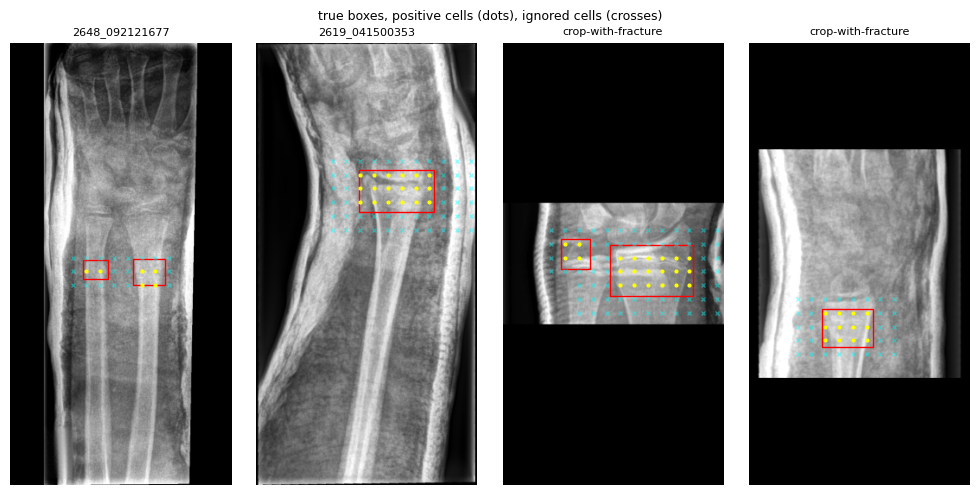

In [17]:
def plot_targets(ax, image, box_list, image_objectness, title):
    ax.imshow(image, cmap='gray')
    draw_boxes(ax, box_list, 'red')
    for i in range(GRID_ROWS):
        for j in range(GRID_COLS):
            cx, cy = cell_center(i, j)
            if image_objectness[i, j] == 1:
                ax.plot(cx, cy, 'o', color='yellow', markersize=2)
            elif image_objectness[i, j] == -1:
                ax.plot(cx, cy, 'x', color='cyan', markersize=3, alpha=0.4)
    ax.set_title(title, fontsize=8)
    ax.axis('off')


fractured_rows = np.nonzero((graz['label'] == 1).to_numpy())[0]
partner_rows = np.nonzero(extra_labels == 1)[0]
original_picks = plot_rng.choice(fractured_rows, size=2, replace=False)
extra_picks = plot_rng.choice(partner_rows, size=2, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(10, 5))
for ax, k in zip(axes[:2], original_picks):
    plot_targets(ax, images[k], original_box_lists[k], objectness[k], graz.at[k, 'filestem'][:14])
for ax, k in zip(axes[2:], extra_picks):
    plot_targets(ax, cast_pair_images[k], extra_box_lists[k], extra_objectness[k], 'crop-with-fracture')
plt.suptitle('true boxes, positive cells (dots), ignored cells (crosses)', fontsize=9)
plt.tight_layout()
plt.show()

## 4. YOLO export

YOLOv8 reads image files and one label file per image. This part only changes the format: same images, splits and boxes.
Each label line is `0 center_x center_y width height`, with x and width divided by 256 and y and height divided by 512. Normals and fracture-free crops get an empty label file.
Runs only if `MAKE_YOLO_EXPORT` is True, and skips writing if `yolo_dataset/` already exists (delete it to redo).

In [18]:
def write_yolo_image(image, box_list, folder, filestem):
    image_dir = YOLO_DIR / 'images' / folder
    label_dir = YOLO_DIR / 'labels' / folder
    cv2.imwrite(str(image_dir / f'{filestem}.png'), image)
    lines = []
    for x0, y0, x1, y1 in box_list:
        center_x = (x0 + x1) / 2 / IMAGE_W
        center_y = (y0 + y1) / 2 / IMAGE_H
        width = (x1 - x0) / IMAGE_W
        height = (y1 - y0) / IMAGE_H
        lines.append(f'0 {center_x:.6f} {center_y:.6f} {width:.6f} {height:.6f}')
    (label_dir / f'{filestem}.txt').write_text('\n'.join(lines))


YOLO_FOLDERS = ['train', 'val', 'test', 'train_cast_pairs']

if MAKE_YOLO_EXPORT and not YOLO_DIR.exists():
    for folder in YOLO_FOLDERS:
        (YOLO_DIR / 'images' / folder).mkdir(parents=True)
        (YOLO_DIR / 'labels' / folder).mkdir(parents=True)

    for row_number, row in enumerate(tqdm(graz.itertuples(), total=len(graz))):
        write_yolo_image(np.asarray(images[row_number]), original_box_lists[row_number], row.split, row.filestem)
    for row_number, row in enumerate(tqdm(cast_pairs.itertuples(), total=len(cast_pairs))):
        write_yolo_image(cast_pair_images[row_number], extra_box_lists[row_number], 'train_cast_pairs', row.filestem)

    yaml_start = f'path: {YOLO_DIR.as_posix()}\n'
    yaml_end = 'val: images/val\ntest: images/test\nnames:\n  0: fracture\n'
    (YOLO_DIR / 'data.yaml').write_text(yaml_start + 'train: images/train\n' + yaml_end)
    (YOLO_DIR / 'data_all-castpairs.yaml').write_text(yaml_start + 'train: [images/train, images/train_cast_pairs]\n' + yaml_end)


  0%|          | 0/20327 [00:00<?, ?it/s]


  0%|          | 48/20327 [00:00<00:44, 454.07it/s]


  0%|          | 99/20327 [00:00<00:43, 460.05it/s]


  1%|          | 145/20327 [00:00<00:44, 451.01it/s]


  1%|          | 191/20327 [00:00<00:52, 381.67it/s]


  1%|          | 242/20327 [00:00<00:48, 410.88it/s]

... (517 outputs left out)


 97%|█████████▋| 6791/7018 [00:11<00:00, 733.78it/s]


 98%|█████████▊| 6867/7018 [00:11<00:00, 739.34it/s]


 99%|█████████▉| 6948/7018 [00:11<00:00, 750.10it/s]


100%|██████████| 7018/7018 [00:11<00:00, 598.22it/s]

Checks: file counts per folder, empty label files exactly for label 0, and label files read back to the CSV boxes within 0.1 px.

train: 14182 images, 14182 label files


val: 3202 images, 3202 label files


test: 2943 images, 2943 label files


train_cast_pairs: 7018 images, 7018 label files


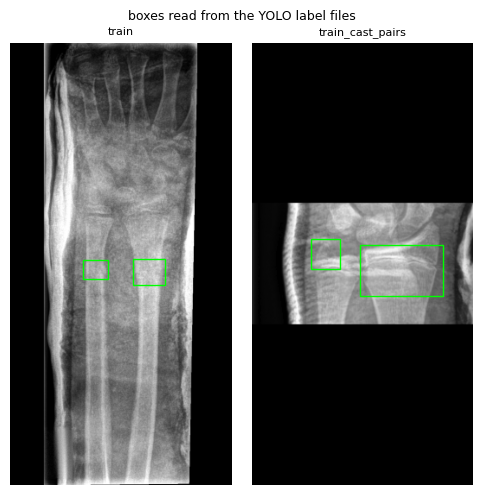

In [19]:
def read_yolo_boxes(label_path):
    """Boxes in pixels from one YOLO label file."""
    box_list = []
    for line in label_path.read_text().splitlines():
        _, center_x, center_y, width, height = [float(value) for value in line.split()]
        box_list.append(((center_x - width / 2) * IMAGE_W, (center_y - height / 2) * IMAGE_H,
                         (center_x + width / 2) * IMAGE_W, (center_y + height / 2) * IMAGE_H))
    return box_list


if MAKE_YOLO_EXPORT:
    tables = {folder: graz[graz['split'] == folder] for folder in ['train', 'val', 'test']}
    tables['train_cast_pairs'] = cast_pairs
    for folder in YOLO_FOLDERS:
        n_png = len(list((YOLO_DIR / 'images' / folder).glob('*.png')))
        n_txt = len(list((YOLO_DIR / 'labels' / folder).glob('*.txt')))
        print(f'{folder}: {n_png} images, {n_txt} label files')
        assert n_png == len(tables[folder]) and n_txt == n_png

        for row in tables[folder].itertuples():
            is_empty = (YOLO_DIR / 'labels' / folder / f'{row.filestem}.txt').stat().st_size == 0
            assert is_empty == (row.label == 0), f'{row.filestem}: empty label file does not match label'

    check_rng = np.random.default_rng(SEED)
    for row_number in check_rng.choice(fractured_rows, size=20, replace=False):
        row = graz.iloc[row_number]
        read_back = read_yolo_boxes(YOLO_DIR / 'labels' / row['split'] / f'{row["filestem"]}.txt')
        assert np.abs(np.array(sorted(read_back)) - np.array(sorted(original_box_lists[row_number]))).max() < 0.1
    for row_number in check_rng.choice(partner_rows, size=20, replace=False):
        filestem = cast_pairs.at[row_number, 'filestem']
        read_back = read_yolo_boxes(YOLO_DIR / 'labels' / 'train_cast_pairs' / f'{filestem}.txt')
        assert np.abs(np.array(sorted(read_back)) - np.array(sorted(extra_box_lists[row_number]))).max() < 0.1

    fig, axes = plt.subplots(1, 2, figsize=(5, 5))
    original_row = graz.iloc[original_picks[0]]
    partner_stem = cast_pairs.at[extra_picks[0], 'filestem']
    for ax, folder, filestem in [(axes[0], original_row['split'], original_row['filestem']), (axes[1], 'train_cast_pairs', partner_stem)]:
        ax.imshow(cv2.imread(str(YOLO_DIR / 'images' / folder / f'{filestem}.png'), cv2.IMREAD_GRAYSCALE), cmap='gray')
        draw_boxes(ax, read_yolo_boxes(YOLO_DIR / 'labels' / folder / f'{filestem}.txt'), 'lime')
        ax.set_title(folder, fontsize=8)
        ax.axis('off')
    plt.suptitle('boxes read from the YOLO label files', fontsize=9)
    plt.tight_layout()
    plt.show()

## Loading in later notebooks

```python
targets = np.load(PROCESSED_DATA_DIR / 'graz_cell_targets.npz')        # same row order as graz.csv
objectness, distances = targets['objectness'], targets['distances']   # (n, 32, 16) int8, (n, 32, 16, 4) float32

cast_pairs = pd.read_csv(PROCESSED_DATA_DIR / 'graz_cast_pairs.csv')
cast_pair_images = np.load(PROCESSED_DATA_DIR / 'graz_cast_pairs_256x512_u8.npy', mmap_mode='r')  # same row order
cast_pair_targets = np.load(PROCESSED_DATA_DIR / 'graz_cast_pairs_cell_targets.npz')
```